# Exercise 38 – Global minimum of a Lennard-Jones-Gauss cluster

**Week 7 · Global optimisation and periodic systems**

The Lennard-Jones-Gauss potential

$$V(r) = \frac{1}{r^{12}} - \frac{2}{r^{6}} - \varepsilon\,e^{-(r-r_0)^2/2\sigma^2},
  \qquad \varepsilon = 1,\ r_0 = 1.7,\ \sigma^2 = 0.02$$

has two minima: the Lennard-Jones one at $r = 1$ and a Gaussian well at
$r = 1.7$. The competition between them gives 12-atom clusters a complicated
energy landscape. We compare steepest descent from random starts with basin
hopping. (The same cluster is optimised with PyTorch in exercise 47.)

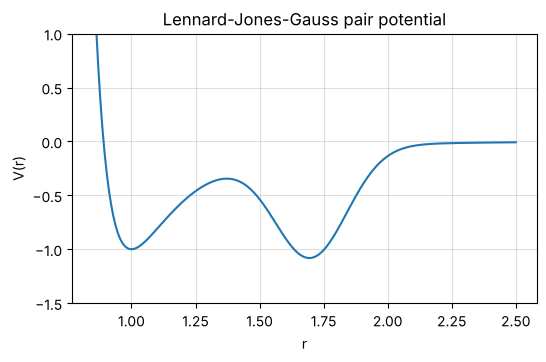

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import basinhopping

from comphy.atoms import Cluster, LennardJonesGauss, line_search_relax, random_positions

rng = np.random.default_rng(0)
calc = LennardJonesGauss(eps=1.0, r0=1.7, sigma_squared=0.02)

r = np.linspace(0.85, 2.5, 400)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(r, calc.V(r))
ax.set(xlabel="r", ylabel="V(r)", ylim=(-1.5, 1), title="Lennard-Jones-Gauss pair potential")
ax.grid(True, alpha=0.4)
plt.show()

## Steepest descent from random starts

In [2]:
results = []
for _ in range(10):
    cluster = Cluster(calc, random_positions(12, 3.0, min_distance=0.9, rng=rng))
    start = cluster.positions.copy()
    line_search_relax(cluster, max_steps=2000, fmax=0.01)
    results.append((cluster.energy, start, cluster.positions.copy()))
energies = sorted(e for e, _, _ in results)
print("energies after steepest descent:", np.round(energies, 3))

energies after steepest descent: [-25.431 -25.053 -24.302 -23.602 -23.457 -23.106 -22.913 -21.179 -21.108
 -20.899]


## Basin hopping

best steepest descent: -25.431   basin hopping: -42.720


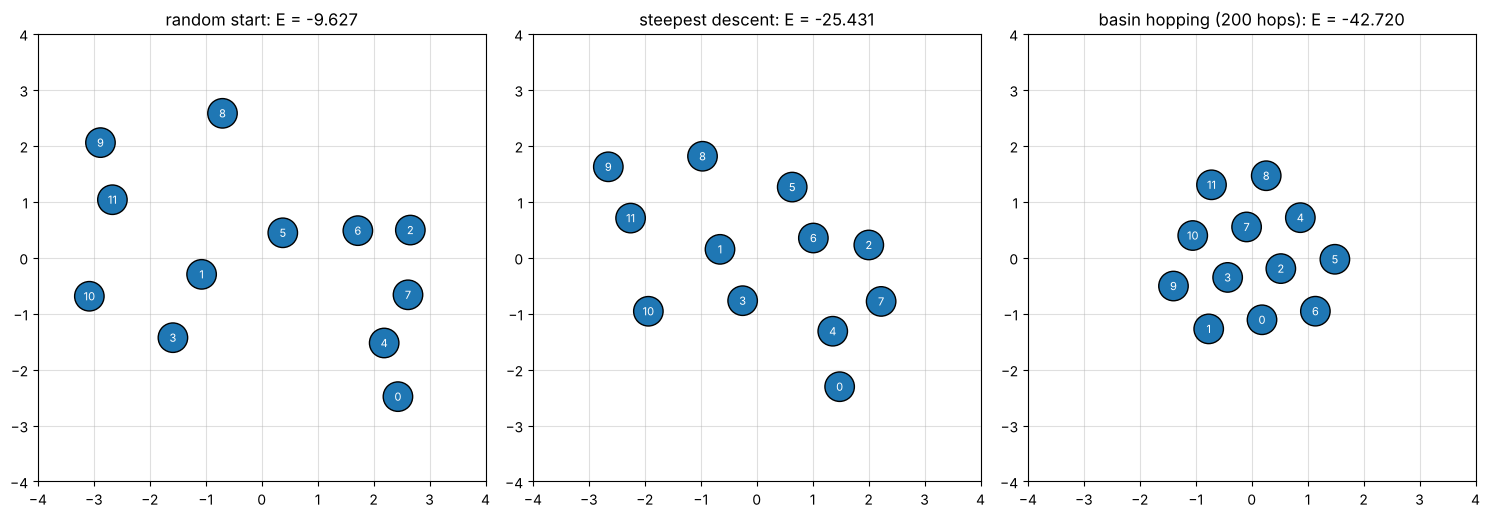

In [3]:
def energy_and_gradient(flat):
    pos = flat.reshape(-1, 2)
    return calc.energy(pos), -calc.forces(pos).ravel()


best_sd = min(results, key=lambda t: t[0])
bh = basinhopping(energy_and_gradient, best_sd[1].ravel(), niter=200, T=0.5, stepsize=0.5, seed=2,
                  minimizer_kwargs=dict(jac=True, method="L-BFGS-B"))
print(f"best steepest descent: {best_sd[0]:.3f}   basin hopping: {bh.fun:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, pos, title in [(axes[0], best_sd[1], "random start"),
                       (axes[1], best_sd[2], "steepest descent"),
                       (axes[2], bh.x.reshape(-1, 2), "basin hopping (200 hops)")]:
    pos = pos - pos.mean(axis=0)
    Cluster(calc, pos).draw(ax, size=450, labels=True)
    ax.set(xlim=(-4, 4), ylim=(-4, 4))
    ax.set_title(f"{title}: {ax.get_title()}")
    ax.grid(True, alpha=0.4)
fig.tight_layout()
plt.show()

Steepest descent ends in a different, poor local minimum from every start,
while basin hopping keeps improving by hopping between minima and reaches
$E \approx -42.7$ – far below the $\approx -35$ found with multi-start gradient
descent in exercise 47.

The best cluster is a compact patch of the triangular lattice. That is no
coincidence: nearest neighbours sit in the Lennard-Jones minimum at $r = 1$,
and the second neighbours of a triangular lattice are at $\sqrt3 \approx 1.73$
– right in the Gaussian well at $r_0 = 1.7$.